# Öncelik 2 — SDF Dice + Scatter (Tema A)

"bantlarda düşük ama globalde yüksek — neden? scatter plot ile bakalım, Dice'a bakalım."


* **Task 1** — bozuk/temiz girdi → tahmin SDF → ikili köprü ara-adım görseli.
* **Task 2** — SDF tahmini ↔ **temiz referans** Dice (hem temiz hem bozuk girdi için), ayrıca recon↔girdi (QC skoru).
* **Task 3** — slayt 7'yi **Dice scatter** olarak yeniden üret: global ρ neden yüksek ama bant-içi ρ neden düşük (menzil kısıtlaması / range restriction).

**standart (binary) maske modeli** ve **SDF modeli** AYRI AYRI değerlendirilir (`wp2_base` vs `wp3_sdf`).

> Ortam: CUDA environment

## 0) Kurulum + iki modelin yüklenmesi

In [8]:
import sys
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
for p in (PROJECT_ROOT, PROJECT_ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from data import load_config
from train import resolve_device, set_seed
import evaluate_correlation_3d as ev3d
import evaluate_correlation_3d_vq as ev3dvq
from evaluate_correlation_3d_vq import load_model
from evaluate_correlation_3d_sdf import load_sdf_model
from quality.score import DICE_BANDS, correlation, banded_correlation

EPS = 1e-6
print("proje kok:", PROJECT_ROOT)

proje kok: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality


In [2]:
config = load_config(str(PROJECT_ROOT / "configs" / "vae3d_vq.yaml"))
device = resolve_device(str(config["train"]["device"]))

# slayt 7 ile ayni ikili: binary baseline (wp2_base) vs SDF-VQ (wp3_sdf)
BINARY_CKPT = PROJECT_ROOT / "outputs" / "checkpoints" / "vae3d_wp2_base_best.pt"
SDF_CKPT    = PROJECT_ROOT / "outputs" / "checkpoints" / "vae3d_wp3_sdf_best.pt"
bin_model = load_model(BINARY_CKPT, device)
sdf_model = load_sdf_model(SDF_CKPT, device)
print("binary + SDF modelleri yuklendi | cihaz:", device)

binary + SDF modelleri yuklendi | cihaz: cuda


## 1) Değerlendirme seti (slayt ile aynı sınav: seed=42, n_per_mask=5)

Aynı degradasyon protokolü. `block = 1 + n_per_mask`; her hacmin temiz referansı `masks[(i//block)*block]`.

In [4]:
SEED = 42
N_PER_MASK = 5
set_seed(SEED)
clean = ev3d.load_clean_volumes(config, "test", None, SEED)
degrader = ev3d.calibrate_degrader(config, clean, SEED)
masks, true_dice, is_clean = ev3d.build_eval_set(clean, degrader, N_PER_MASK, SEED)
block = 1 + N_PER_MASK
references = np.stack([masks[(i // block) * block] for i in range(len(masks))])
print(f"toplam {len(masks)} hacim | temiz {int(is_clean.sum())} | bozuk {int((~is_clean).sum())} | block={block}")

toplam 282 hacim | temiz 47 | bozuk 235 | block=6


## Task 1 — bozuk/temiz girdi → tahmin SDF → ikili köprü

Ara adım: `predict_sdf` ham sürekli SDF'i (dış +, iç −, sınır ~0) döndürür; köprü `sdf<0 → iç`. Solda girdi, ortada SDF (renkli, ±3), sağda köprü çıktısı. Başlıkta self-Dice (köprü ↔ girdi).

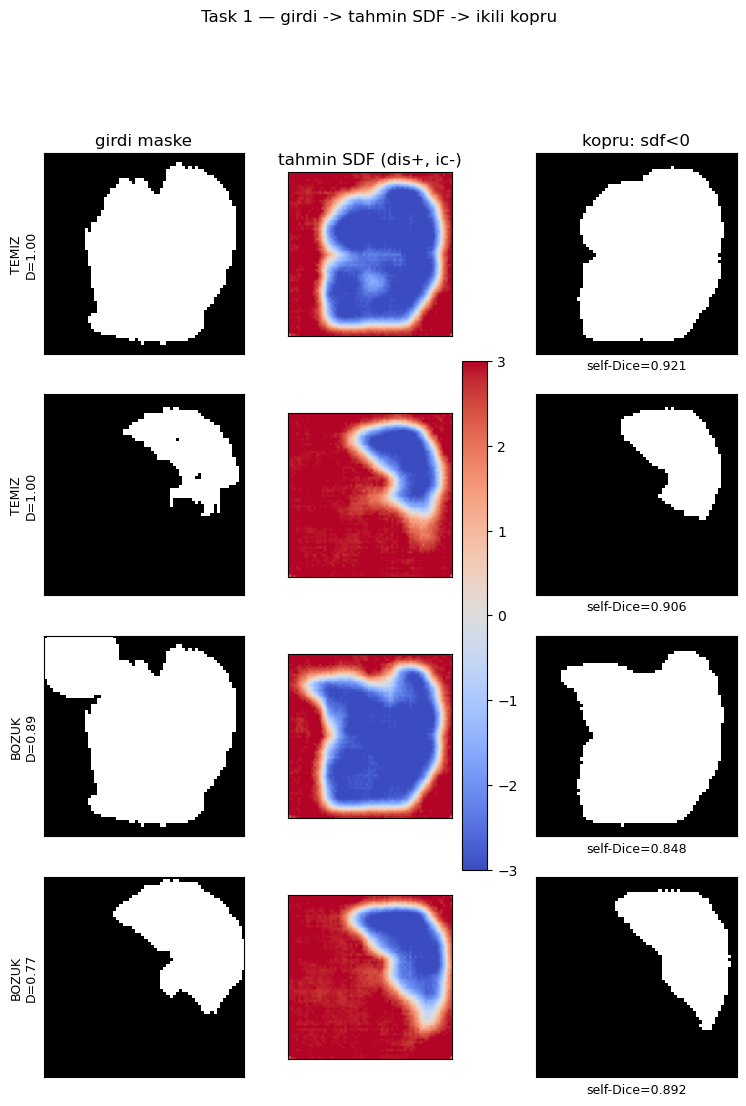

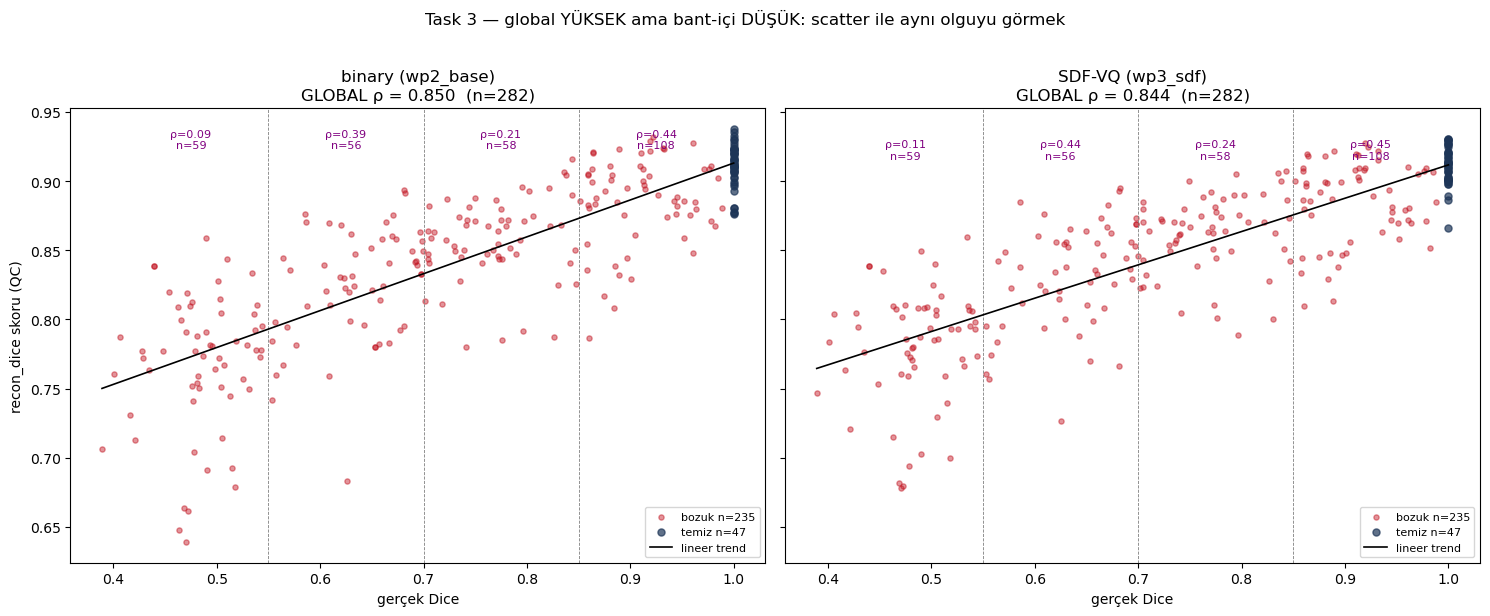

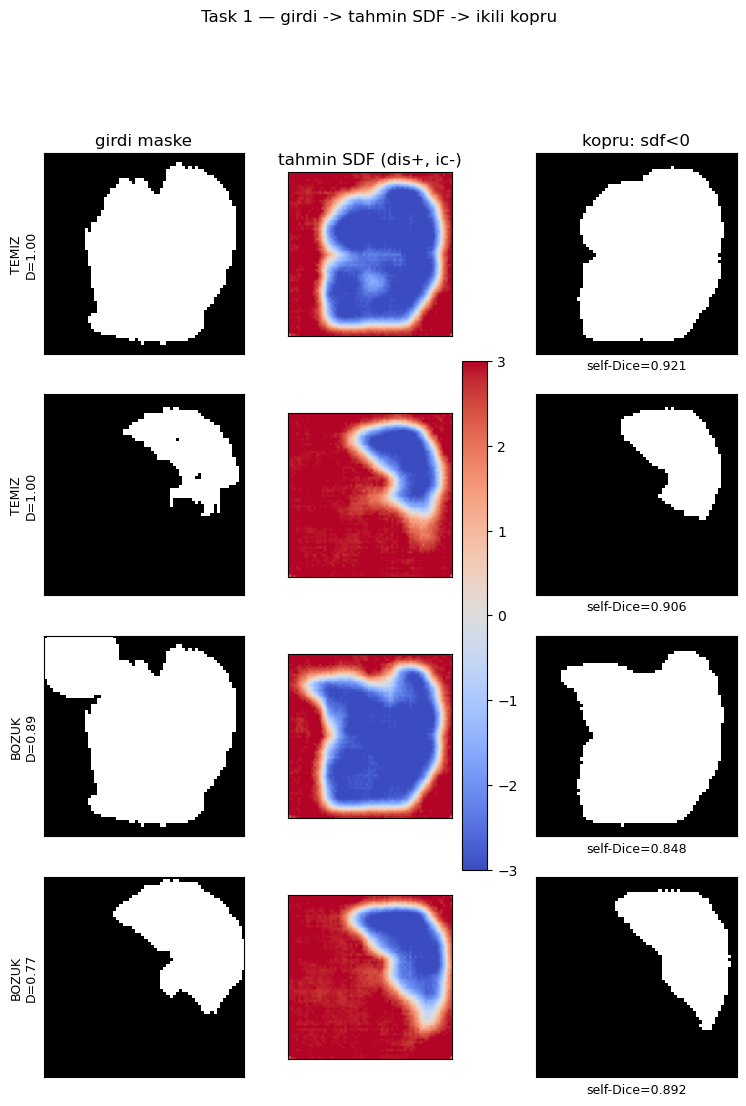

In [9]:
@torch.no_grad()
def predict_sdf_vol(mask_np):
    x = torch.from_numpy(mask_np.astype(np.float32))[None, None].to(device)
    return sdf_model.predict_sdf(x)[0, 0].cpu().numpy()


def dice_np(a, b):
    a = a > 0.5; b = b > 0.5
    return float((2 * np.logical_and(a, b).sum() + 1) / (a.sum() + b.sum() + 1))


deg_idx = [i for i in range(len(masks)) if not is_clean[i]]
cl_idx = [i for i in range(len(masks)) if is_clean[i]]
show = [cl_idx[0], cl_idx[1], deg_idx[0], deg_idx[5]]   # 2 temiz + 2 bozuk

fig, axes = plt.subplots(len(show), 3, figsize=(9, 3 * len(show)))
im = None
for r, gi in enumerate(show):
    inp = masks[gi]; sdf = predict_sdf_vol(inp); binr = (sdf < 0).astype(np.float32)
    zc = inp.shape[0] // 2
    kind = "TEMIZ" if is_clean[gi] else "BOZUK"
    axes[r, 0].imshow(inp[zc], cmap="gray")
    axes[r, 0].set_ylabel(f"{kind}\nD={true_dice[gi]:.2f}", fontsize=9)
    im = axes[r, 1].imshow(sdf[zc], cmap="coolwarm", vmin=-3, vmax=3)
    axes[r, 2].imshow(binr[zc], cmap="gray")
    axes[r, 2].set_xlabel(f"self-Dice={dice_np(binr, inp):.3f}", fontsize=9)
    if r == 0:
        axes[r, 0].set_title("girdi maske")
        axes[r, 1].set_title("tahmin SDF (dis+, ic-)")
        axes[r, 2].set_title("kopru: sdf<0")
    for c in range(3):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
fig.colorbar(im, ax=axes[:, 1], shrink=0.55)
fig.suptitle("Task 1 — girdi -> tahmin SDF -> ikili kopru", y=1.0)
plt.show()

## Task 2 — SDF Dice: recon ↔ temiz referans (+ recon ↔ girdi)

İki farklı Dice:
* **recon ↔ girdi** = QC skoru (`recon_dice`). Model girdiyi ne kadar iyi geri üretiyor.
* **recon ↔ temiz referans** = modelin bozuğu ne kadar 'temizlediği' (denoiser davranışı).

Hem **temiz** hem **bozuk** girdi için, binary ve SDF ayrı ayrı.

In [10]:
@torch.no_grad()
def reconstruct_binary(model, vols, batch=8):
    outs = []
    for s in range(0, len(vols), batch):
        x = torch.from_numpy(vols[s:s + batch].astype(np.float32)).unsqueeze(1).to(device)
        rec = (model.reconstruct(x) > 0.5).float()[:, 0].cpu().numpy()
        outs.append(rec)
    return np.concatenate(outs)


def dice_arr(a, b):
    a = a > 0.5; b = b > 0.5; dims = (1, 2, 3)
    inter = np.logical_and(a, b).sum(dims)
    denom = a.sum(dims) + b.sum(dims)
    return (2 * inter + 1) / (denom + 1)


rec_bin = reconstruct_binary(bin_model, masks)
rec_sdf = reconstruct_binary(sdf_model, masks)

print(f"{'model':18s} {'girdi':6s} {'Dice(recon,girdi)':>18s} {'Dice(recon,referans)':>22s}")
for name, rec in [("binary(wp2_base)", rec_bin), ("SDF(wp3_sdf)", rec_sdf)]:
    d_inp = dice_arr(rec, masks)
    d_ref = dice_arr(rec, references)
    for tag, sel in [("TEMIZ", is_clean), ("BOZUK", ~is_clean)]:
        print(f"{name:18s} {tag:6s} {d_inp[sel].mean():18.3f} {d_ref[sel].mean():22.3f}")

model              girdi   Dice(recon,girdi)   Dice(recon,referans)
binary(wp2_base)   TEMIZ               0.911                  0.911
binary(wp2_base)   BOZUK               0.834                  0.734
SDF(wp3_sdf)       TEMIZ               0.911                  0.911
SDF(wp3_sdf)       BOZUK               0.840                  0.737


## Task 3 — slayt 7'nin SCATTER hali 

x = gerçek Dice, y = `recon_dice` (QC skoru). Dikey kesikli çizgiler bant sınırları. Her bant için mor `ρ, n` yazılı; başlıkta GLOBAL ρ.

**Beklenen okuma:** bulut bir bütün olarak güçlü monoton (global ρ yüksek), ama tek bir dar bandın içinde y ekseni dağınık bir küme → bant-içi ρ düşük.

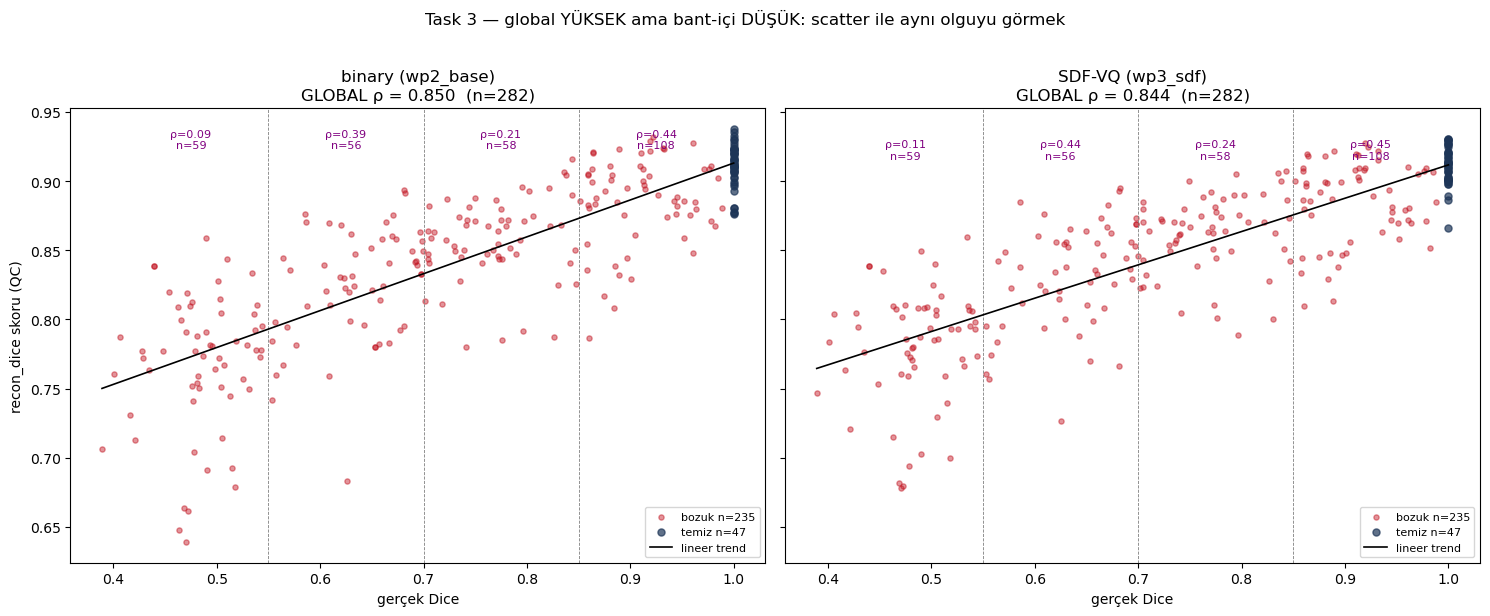

model                 global ρ | bant-içi ρ  [.40-.55] [.55-.70] [.70-.85] [.85-1.0]
binary(wp2_base)         0.850 |            0.09   0.39   0.21   0.44
SDF(wp3_sdf)             0.844 |            0.11   0.44   0.24   0.45


In [11]:
scores_bin = ev3dvq.score_masks_vq(bin_model, masks, device)["recon_dice"]
scores_sdf = ev3dvq.score_masks_vq(sdf_model, masks, device)["recon_dice"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, (name, sc) in zip(axes, [("binary (wp2_base)", scores_bin), ("SDF-VQ (wp3_sdf)", scores_sdf)]):
    g = correlation(sc, true_dice)
    bands = banded_correlation(sc, true_dice)
    deg = ~is_clean
    ax.scatter(true_dice[deg], sc[deg], s=14, alpha=0.45, c="#c1121f", label=f"bozuk n={int(deg.sum())}")
    ax.scatter(true_dice[is_clean], sc[is_clean], s=26, alpha=0.7, c="#1d3557", label=f"temiz n={int(is_clean.sum())}")
    for lo, hi in DICE_BANDS[:-1]:
        ax.axvline(hi, color="grey", lw=0.6, ls="--")
    order = np.argsort(true_dice)
    coeffs = np.polyfit(true_dice, sc, 1)
    ax.plot(true_dice[order], np.polyval(coeffs, true_dice[order]), "k-", lw=1.2, label="lineer trend")
    ytop = sc.max()
    for b in bands:
        xc = (b["band_lo"] + b["band_hi"]) / 2.0
        ax.text(xc, ytop, f"ρ={b['spearman']:.2f}\nn={b['n']}", ha="center", va="top",
                fontsize=8, color="purple")
    ax.set_title(f"{name}\nGLOBAL ρ = {g['spearman']:.3f}  (n={g['n']})")
    ax.set_xlabel("gerçek Dice")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("recon_dice skoru (QC)")
fig.suptitle("Task 3 — global YÜKSEK ama bant-içi DÜŞÜK: scatter ile aynı olguyu görmek", y=1.02)
fig.tight_layout()
plt.show()

print(f"{'model':20s} {'global ρ':>9s} | bant-içi ρ  [.40-.55] [.55-.70] [.70-.85] [.85-1.0]")
for name, sc in [("binary(wp2_base)", scores_bin), ("SDF(wp3_sdf)", scores_sdf)]:
    g = correlation(sc, true_dice)
    bands = banded_correlation(sc, true_dice)
    bs = "   ".join(f"{b['spearman']:.2f}" for b in bands)
    print(f"{name:20s} {g['spearman']:9.3f} |            {bs}")

## Neden global yüksek ama bant-içi düşük? (YORUM)

**Menzil kısıtlaması (range restriction).** Spearman ρ, bir eksende sıralama değişimini ölçer.

* **Global:** gerçek Dice 0.40'tan 1.00'a kadar geniş yayılır. Kötü maskeler düşük skor, temiz maskeler yüksek skor → güçlü monoton ilişki → ρ yüksek (~0.85).
* **Bant içi:** ör. `[0.85-1.00]` bandında tüm noktaların gerçek Dice'ı neredeyse aynıdır (dar aralık). Bu dar aralıkta skorun kalan oynaması çoğunlukla **gürültü**dür (aynı kalitedeki maskeler arası küçük fark). Sıralanacak gerçek sinyal kalmadığı için ρ düşer.

Yani düşük bant-içi ρ bir  istatistiksel bir olgudur: skor zaten kaliteyi ayırt ediyor (global), ama neredeyse-eşit kalitede iki maskeyi ince ayrımla sıralamak beklenemez. Scatter'da bu, dar bir dikey şeridin içinde noktaların bulut oluşturması olarak görünür — trend bütünde nettir.